# PCA and Kalman statistical arbitrage

Compare two historical samples using the same four 15-stock universes and model settings. Every figure starts after all portfolios are active and uses common calendar bounds across the four universes. Initial no-position history is excluded from the reported performance.

Both samples are shown. Selecting the better one after looking at results is historical selection, not a new untouched test.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from equity_stat_arb.period_comparison import run
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/equity_stat_arb").exists())
manifest = run(ROOT)
OUTPUT = ROOT / "artifacts/period_comparison"
metrics = pd.read_csv(OUTPUT / "metrics.csv")
daily = pd.read_parquet(OUTPUT / "daily_returns.parquet")
display(pd.DataFrame(manifest["samples"]))

Evaluating 2017-2021: technology


Evaluating 2017-2021: financial


Evaluating 2017-2021: energy


Evaluating 2017-2021: uk_external


Evaluating 2022-2026: technology


Evaluating 2022-2026: financial


Evaluating 2022-2026: energy


Evaluating 2022-2026: uk_external


   sample    universe                         variant  sharpe    cagr  max_drawdown
2017-2021  technology            Fixed Kalman / equal  0.5584  0.0561       -0.1413
2017-2021  technology Calibrated Kalman / inverse vol  0.2230  0.0189       -0.2153
2017-2021   financial            Fixed Kalman / equal  0.7104  0.0599       -0.1106
2017-2021   financial Calibrated Kalman / inverse vol  0.5198  0.0453       -0.1418
2017-2021      energy            Fixed Kalman / equal  0.2622  0.0274       -0.1623
2017-2021      energy Calibrated Kalman / inverse vol  0.4161  0.0482       -0.1243
2017-2021 uk_external            Fixed Kalman / equal  0.7982  0.0736       -0.1402
2017-2021 uk_external Calibrated Kalman / inverse vol  0.7024  0.0601       -0.1300
2022-2026  technology            Fixed Kalman / equal -0.4082 -0.0690       -0.2730
2022-2026  technology Calibrated Kalman / inverse vol -0.4860 -0.0747       -0.2926
2022-2026   financial            Fixed Kalman / equal -0.2296 -0.0189       

,sample,start,end,zero_exposure_rows
0,2017-2021,2018-07-09,2021-12-31,0
1,2022-2026,2023-07-11,2026-08-07,0


## Data and periods

Adjusted daily closes are downloaded directly from Yahoo Finance through `yfinance` and retained as checksummed local snapshots. All 60 configured stock histories are used; no name is replaced based on returns.

Each experiment restarts the same training and signal-history rules within its own input period: 2017–2021 or January 2022–August 2026. After warmup, the reporting window starts on the first shared date when every universe has positions. US and UK trading-day counts can still differ because of holidays.

The resulting active windows are 9 July 2018–31 December 2021 and 11 July 2023–7 August 2026. All series in a given experiment have exactly the same first and last calendar date. There are no initial zero-exposure rows in the figures.

,universe,first_date,last_date,observations,sha256
0,technology,2017-01-03,2026-08-07,2412,2da61be71549ee05852d0312a880b446a93926df757e6e...
1,financial,2017-01-03,2026-08-07,2412,a98b31d7f7ebbac8796e6efa084ceeed76132b18c2a2c0...
2,energy,2017-01-03,2026-08-07,2412,18b4d1e01ae1fe421f124cee25398a794db2766669848e...
3,uk_external,2017-01-03,2026-08-07,2420,0309df2e0c2d23208553ce5563f6936e49285d98131656...


2017-2021 — active period: 2018-07-09 to 2021-12-31


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
universe,,,,,
energy,0.440,0.416,0.262,0.234,0.262
financial,0.547,0.520,0.710,0.700,0.527
technology,0.410,0.223,0.558,0.337,0.548
uk_external,0.740,0.702,0.798,0.753,0.798


,universe,variant,days,cagr,max_drawdown,average_daily_turnover
2,technology,PCA / equal,879,0.0547,-0.1472,0.0834
6,technology,Fixed Kalman / equal,879,0.0561,-0.1413,0.0834
10,technology,Calibrated Kalman / equal,879,0.0400,-0.1815,0.0842
14,technology,Fixed Kalman / inverse vol,879,0.0316,-0.1793,0.0859
18,technology,Calibrated Kalman / inverse vol,879,0.0189,-0.2153,0.0862
22,financial,PCA / equal,879,0.0418,-0.1123,0.0842
26,financial,Fixed Kalman / equal,879,0.0599,-0.1106,0.0842
30,financial,Calibrated Kalman / equal,879,0.0478,-0.1253,0.0842
34,financial,Fixed Kalman / inverse vol,879,0.0596,-0.1281,0.0851
38,financial,Calibrated Kalman / inverse vol,879,0.0453,-0.1418,0.0851


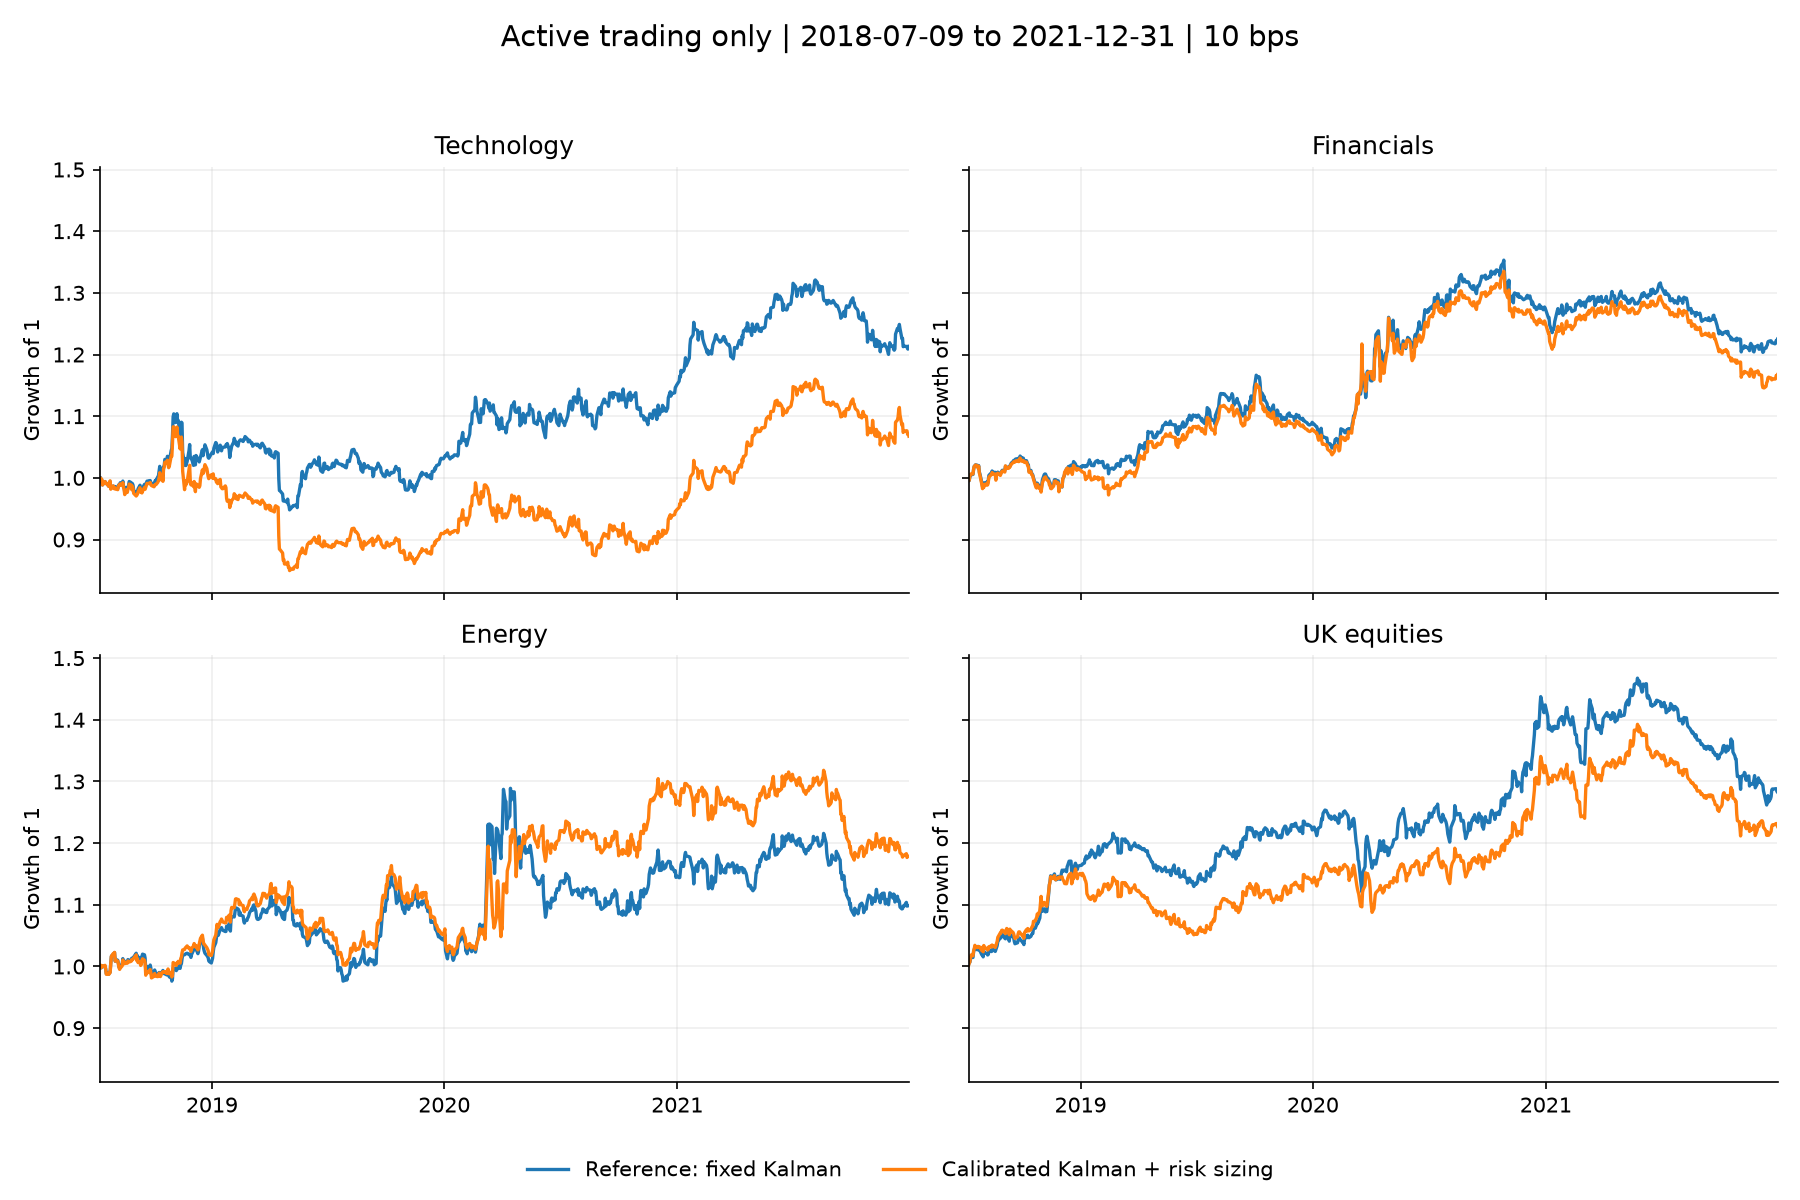

2022-2026 — active period: 2023-07-11 to 2026-08-07


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
universe,,,,,
energy,0.490,0.474,0.382,0.382,0.394
financial,-0.173,-0.208,-0.230,-0.235,-0.115
technology,-0.380,-0.486,-0.408,-0.582,-0.449
uk_external,-0.193,-0.229,-0.092,-0.173,-0.091


,universe,variant,days,cagr,max_drawdown,average_daily_turnover
82,technology,PCA / equal,773,-0.0743,-0.2542,0.0858
86,technology,Fixed Kalman / equal,773,-0.0690,-0.2730,0.0858
90,technology,Calibrated Kalman / equal,773,-0.0664,-0.3107,0.0850
94,technology,Fixed Kalman / inverse vol,773,-0.0858,-0.2903,0.0880
98,technology,Calibrated Kalman / inverse vol,773,-0.0747,-0.2926,0.0870
102,financial,PCA / equal,773,-0.0104,-0.1127,0.0793
106,financial,Fixed Kalman / equal,773,-0.0189,-0.1246,0.0789
110,financial,Calibrated Kalman / equal,773,-0.0151,-0.1206,0.0785
114,financial,Fixed Kalman / inverse vol,773,-0.0194,-0.1271,0.0808
118,financial,Calibrated Kalman / inverse vol,773,-0.0178,-0.1246,0.0806


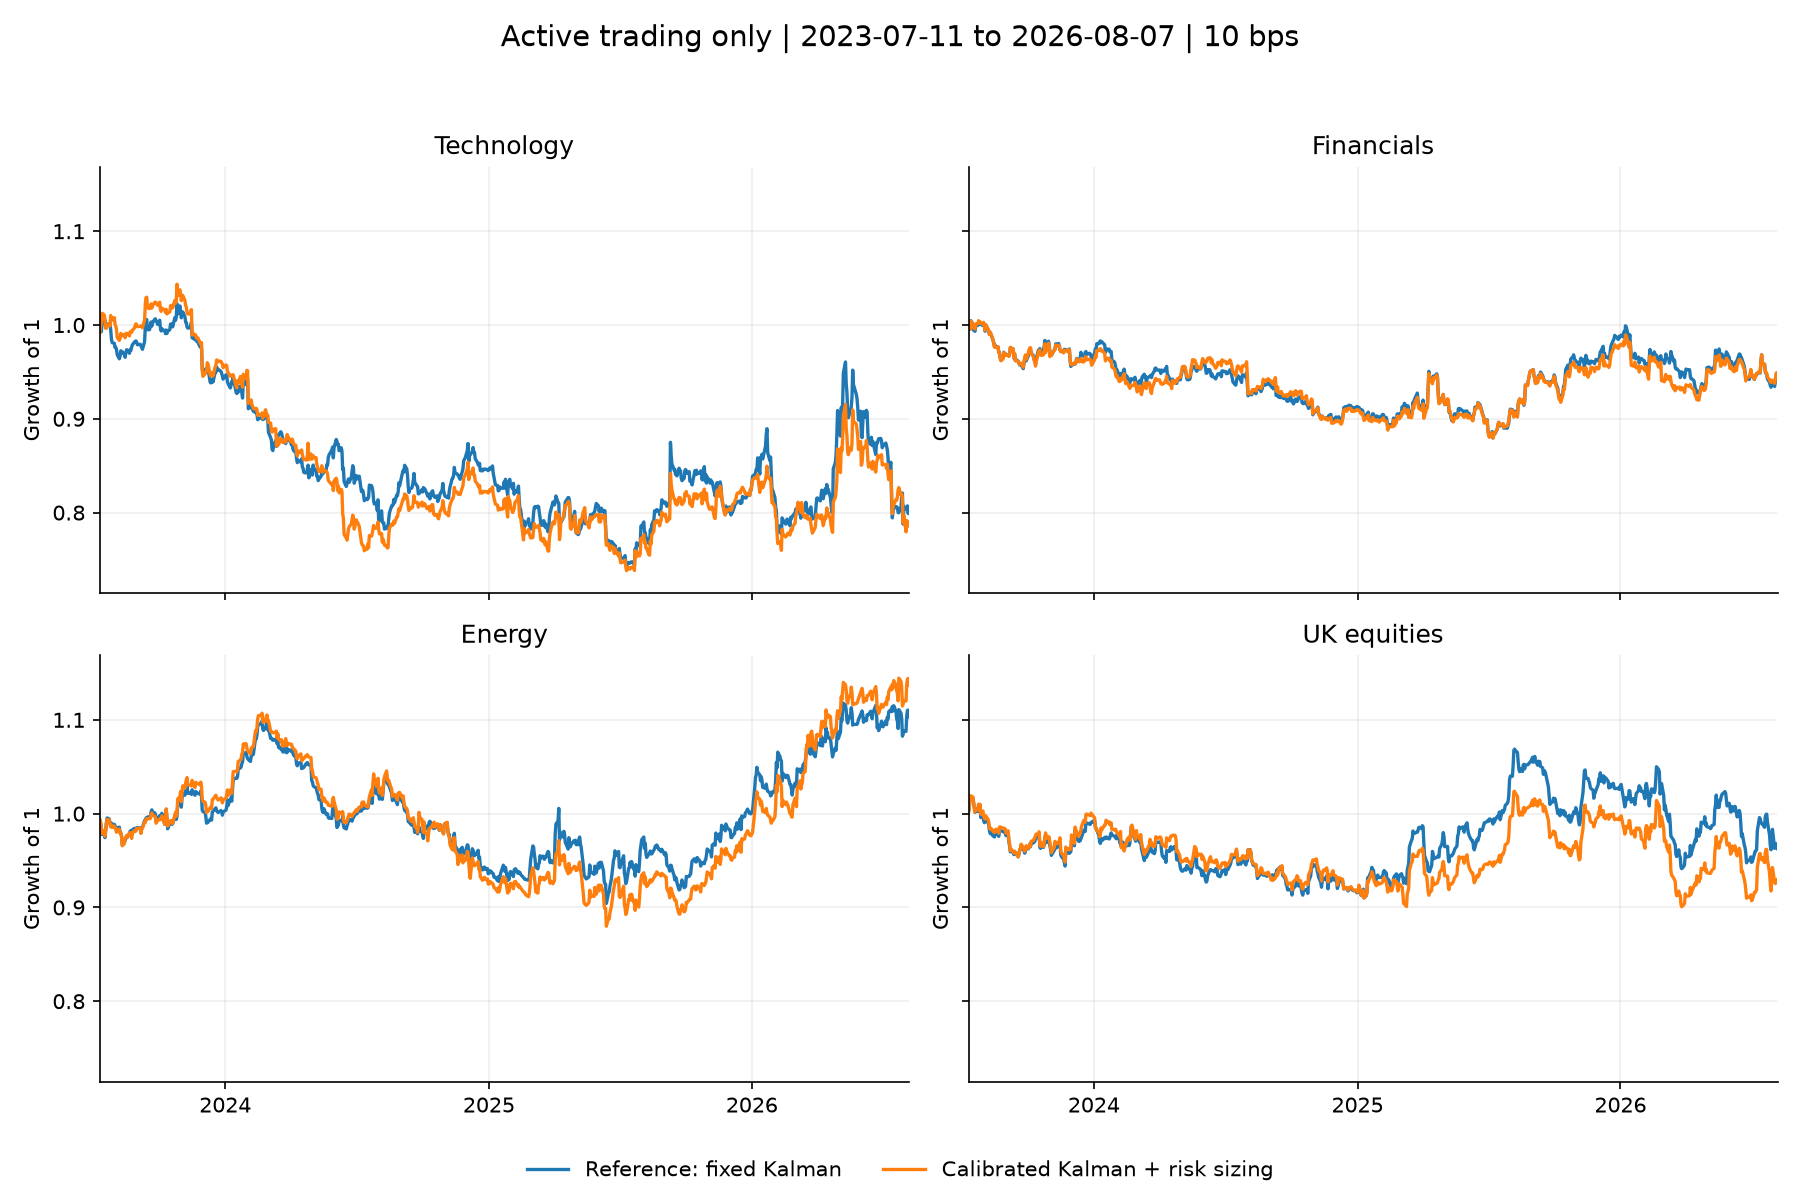

In [2]:
display(pd.DataFrame(manifest["prices"])[["universe", "first_date", "last_date", "observations", "sha256"]])
at_10 = metrics[metrics.cost_bps == 10]
for sample in manifest["samples"]:
    name = sample["sample"]
    print(name, "— active period:", sample["start"], "to", sample["end"])
    subset = at_10[at_10["sample"] == name]
    display(subset.pivot(index="universe", columns="variant", values="sharpe").round(3))
    display(subset[["universe", "variant", "days", "cagr", "max_drawdown", "average_daily_turnover"]].round(4))
    display(Image(filename=str(OUTPUT / (name + ".png"))))

## Models and signals

Correlation PCA uses 126 past trading days, refits every 10 days and retains the factor count required for 55% explained variance.

$$r^{std}_{i,t}=\alpha_{i,t}+\beta_{i,t}^{\top}f_t+\epsilon_{i,t}.$$

Kalman residuals are innovations recorded before updating the state. The filter resets for each PCA basis. The fixed variant uses Q=1e-4. Calibration scores Q=0, 1e-4 or 1e-2 using sequential Gaussian likelihood: the first 84 past observations fit PCA/scaling/noise and the last 42 score the candidates. Production then fits all 126 past observations. No trading profit enters this choice.

The signal ranks negative five-day residual pressure divided by 20-day residual volatility. Three longs and three shorts are selected every 20 days after 252 residual observations of initial history. Inverse-volatility sizing uses raw returns from the preceding 20 days, with 50% per side and a 25% target weight cap.

Targets are lagged one day. Daily weights are treated as constant until the next signal rebalance; costs cover changes in those targets only. Holding drift and weight-maintenance trades are omitted. This remains a simplified research accounting model.

## Cost sensitivity

Every sample uses the same model parameters, allocation rules and turnover-cost convention. The figures highlight fixed Kalman/equal weights against calibrated Kalman/risk sizing; all five variants remain in the tables.

In [3]:
for sample in metrics["sample"].unique():
    for universe in metrics.universe.unique():
        print(sample, universe)
        subset = metrics[(metrics["sample"] == sample) & (metrics.universe == universe)]
        display(subset.pivot(index="cost_bps", columns="variant", values="sharpe").round(3))
selected = at_10[at_10.variant.isin(["Fixed Kalman / equal", "Calibrated Kalman / inverse vol"])]
print("Descriptive average/median across universes, NOT a portfolio Sharpe:")
display(selected.groupby(["sample", "variant"]).sharpe.agg(["mean", "median"]).round(3))

2017-2021 technology


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.603,0.417,0.755,0.535,0.745
5,0.506,0.320,0.657,0.436,0.646
10,0.410,0.223,0.558,0.337,0.548
20,0.217,0.030,0.362,0.140,0.351


2017-2021 financial


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.774,0.749,0.952,0.941,0.777
5,0.661,0.635,0.832,0.821,0.652
10,0.547,0.520,0.710,0.700,0.527
20,0.319,0.290,0.466,0.456,0.275


2017-2021 energy


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.589,0.572,0.410,0.392,0.410
5,0.514,0.494,0.336,0.313,0.336
10,0.440,0.416,0.262,0.234,0.262
20,0.291,0.260,0.114,0.076,0.114


... (8 outputs left out)

2022-2026 uk_external


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.021,-0.010,0.120,0.046,0.122
5,-0.086,-0.119,0.014,-0.063,0.015
10,-0.193,-0.229,-0.092,-0.173,-0.091
20,-0.406,-0.446,-0.302,-0.390,-0.302


Descriptive average/median across universes, NOT a portfolio Sharpe:


mean  median
sample    variant                                       
2017-2021 Calibrated Kalman / inverse vol  0.465   0.468
          Fixed Kalman / equal             0.582   0.634
2022-2026 Calibrated Kalman / inverse vol -0.112  -0.218
          Fixed Kalman / equal            -0.087  -0.161

## Notes

The earlier sample is more favorable overall. Adding calibration and risk sizing helps energy, but does not consistently improve the reference in the other universes. The recent sample is mostly negative, so the favorable earlier result is not evidence of a stable edge across regimes.

Charts use the same axes within each sample, begin with active trading and contain no artificial initial flat year. Metrics are recalculated over those exact calendar bounds; they are not copied from the earlier mixed-period experiment.

Limitations include inspected histories, hand-picked universes, possible survivorship bias, constant-target-weight accounting and omitted borrow/financing/impact costs. Dollar neutrality is not factor neutrality. There is no Robust PCA or C++ implementation.

The separate archived numerical reproduction remains available through `python -m equity_stat_arb.pipeline --verify`. Its mixed-period inputs and initial flat-day convention are not the headline analysis here. Source details are preserved in its manifest.

Run `python -m equity_stat_arb.period_comparison` to regenerate this comparison and `python -m pytest -q` for the numerical checks.